<a href="https://colab.research.google.com/github/Reeman-30/pc-codespaces-test/blob/main/Pertemuan_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import cv2
from google.colab.patches import cv2_imshow

# **PERTEMUAN 4 - PERBAIKAN KUALITAS CITRA PADA DOMAIN FREKUENSI**

## **Transformasi Fourier**

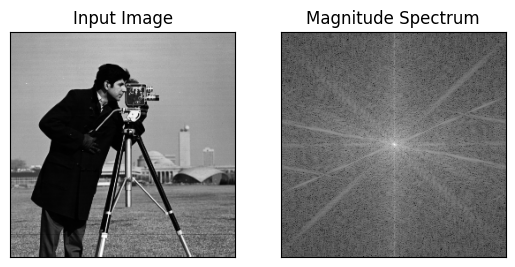

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Footage/camera.tif', 0)

f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
magnitude_spectrum = 20 * np.log(np.abs(fshift))

# print('IMAGE ORIGINAL: ', img)
# print('F: ', f[:1, :1])
# print('FSHIFT: ', fshift[:1])
# print('MAGNITUDE: ', magnitude_spectrum[:1, :1])

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])

plt.show()

### Jet Colormap Image

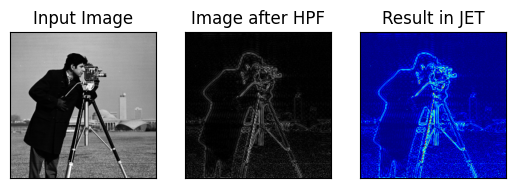

In [ ]:
fshift = np.fft.fftshift(np.fft.fft2(img))

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
fshift[crow - 30:crow + 31, ccol - 30:ccol + 31] = 0

f_ishift = np.fft.ifftshift(fshift)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(img_back, cmap='gray')
plt.title('Image after HPF'), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(img_back, cmap='jet')
plt.title('Result in JET'), plt.xticks([]), plt.yticks([])

plt.show()

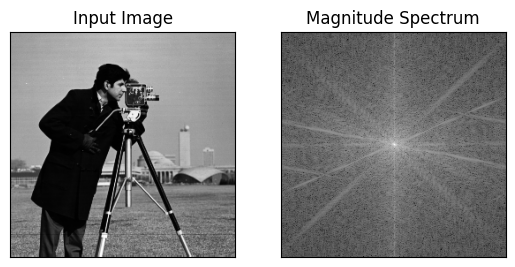

In [ ]:
dft = cv2.dft(np.float32(img), flags = cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20 * np.log(cv2.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])

plt.show()

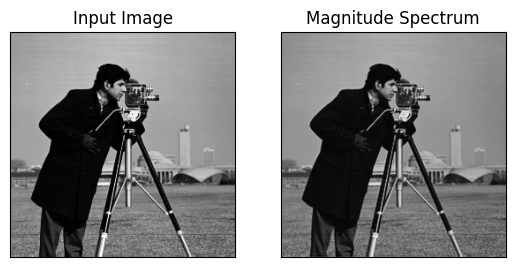

In [ ]:
rows, cols = img.shape
crow, ccol = rows // 2 , cols // 2

mask = np.zeros((rows, cols, 2),np.uint8)
mask[crow-100:crow+100, ccol-100:ccol+100] = 1

fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(fshift)
img_back = cv2.idft(f_ishift)
img_back = cv2.magnitude(img_back[:,:,0],img_back[:,:,1])

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])

plt.show()

## **Optimasi DFT**

### Optimasi Resolusi Pixel

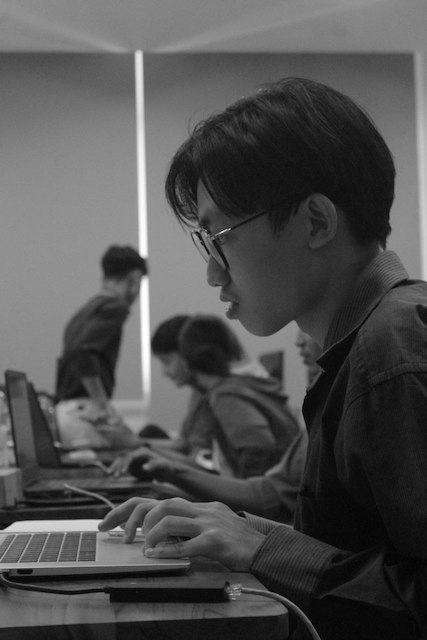

640 427
640 432


In [ ]:
img2 = cv2.imread('/content/drive/MyDrive/Footage/mervin.jpg', 0)
cv2_imshow(img2)
rows,cols = img2.shape
print(rows,cols)

nrows = cv2.getOptimalDFTSize(rows)
ncols = cv2.getOptimalDFTSize(cols)
print(nrows,ncols)

### Perbandingan Performa DFT

In [ ]:
nimg = np.zeros((nrows,ncols))
nimg[:rows,:cols] = img2

%timeit fft1 = np.fft.fft2(img2)
%timeit fft2 = np.fft.fft2(img2,[nrows,ncols])

8.05 ms ± 3.85 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
4.18 ms ± 714 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
%timeit dft1= cv2.dft(np.float32(img),flags=cv2.DFT_COMPLEX_OUTPUT)
%timeit dft2= cv2.dft(np.float32(nimg),flags=cv2.DFT_COMPLEX_OUTPUT)

203 µs ± 3.59 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
1.02 ms ± 142 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


## **Operasi Filter di Domain Frekuensi**

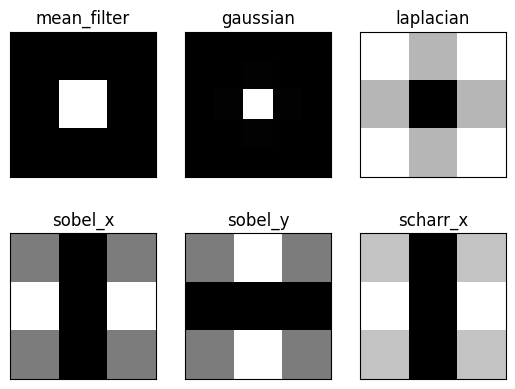

In [ ]:
mean_filter = np.ones((3,3))

x = cv2.getGaussianKernel(5,10)
gaussian = x * x.T

scharr = np.array([
    [-3, 0, 3],
    [-10,0,10],
    [-3, 0, 3]
])

sobel_x= np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y= np.array([
    [-1,-2,-1],
    [0, 0, 0],
    [1, 2, 1]
])

laplacian=np.array([
    [0, 1, 0],
    [1,-4, 1],
    [0, 1, 0]
])

filters = [mean_filter, gaussian, laplacian, sobel_x, sobel_y, scharr]
filter_name = [
    'mean_filter', 'gaussian',
    'laplacian', 'sobel_x',
    'sobel_y', 'scharr_x'
]

fft_filters = [np.fft.fft2(x) for x in filters]
fft_shift = [np.fft.fftshift(y) for y in fft_filters]
mag_spectrum = [np.log(np.abs(z)+1) for z in fft_shift]

for i in range(6):
  plt.subplot(2,3,i+1),plt.imshow(mag_spectrum[i],cmap = 'gray')
  plt.title(filter_name[i]), plt.xticks([]), plt.yticks([])

plt.show()

### Domain Filter - Cartoonify



Domain Filter - Cartoonify


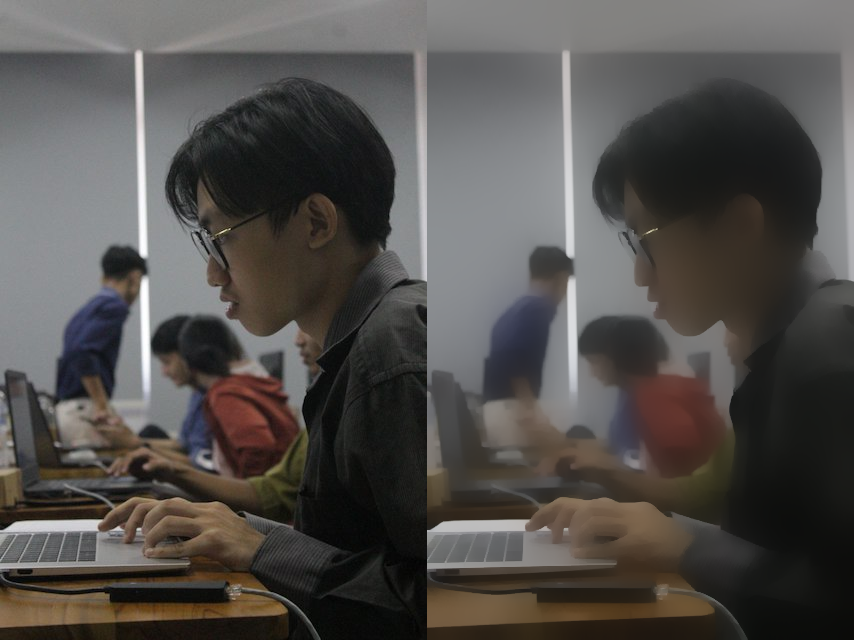

In [ ]:
src = cv2.imread('/content/drive/MyDrive/Footage/mervin.jpg', -1)
DF = cv2.edgePreservingFilter(src, flags=1, sigma_s=60, sigma_r=0.6)

print("Domain Filter - Cartoonify")
cv2_imshow(np.hstack((src, DF)))

### Gaussian Filter

Gaussian Smoothing


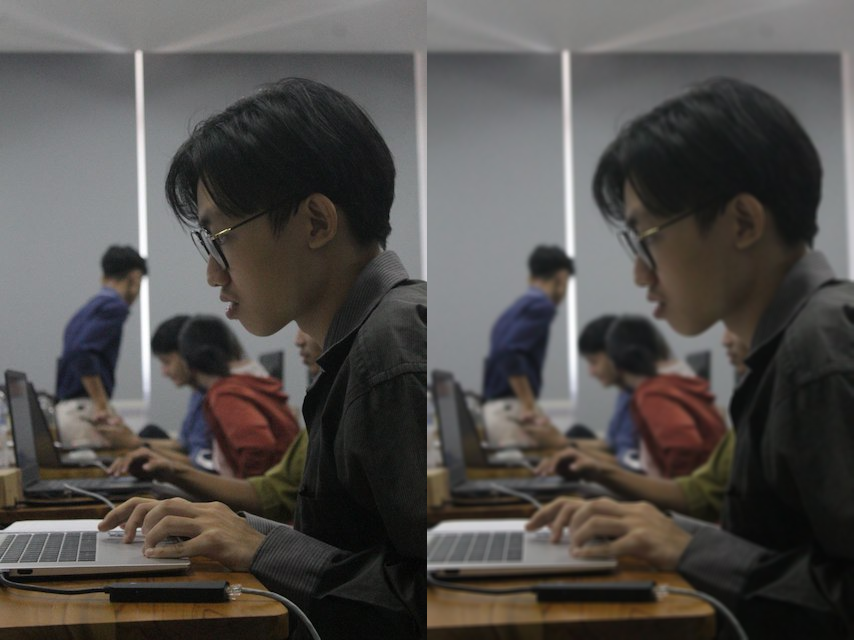

In [ ]:
dst = cv2.GaussianBlur(src,(5, 5),cv2.BORDER_DEFAULT)

print("Gaussian Smoothing")
cv2_imshow(np.hstack((src, dst)))

### Mean Filter

Mean Filter


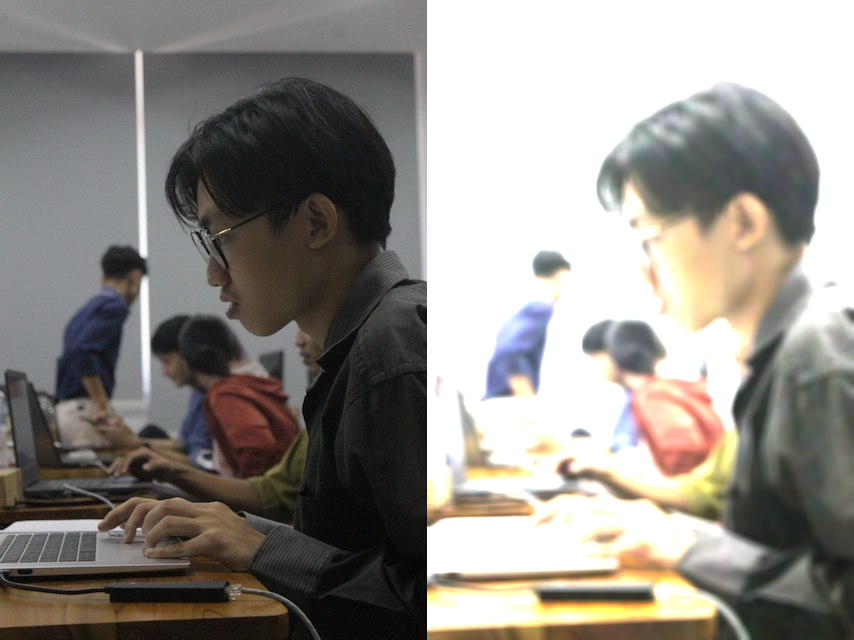

In [ ]:
kernel = np.ones((10, 10), np.float32) / 25

img_mean = cv2.filter2D(src, -1, kernel)

print("Mean Filter")
cv2_imshow(np.hstack((src, img_mean)))

### Median Filter

Median Filter


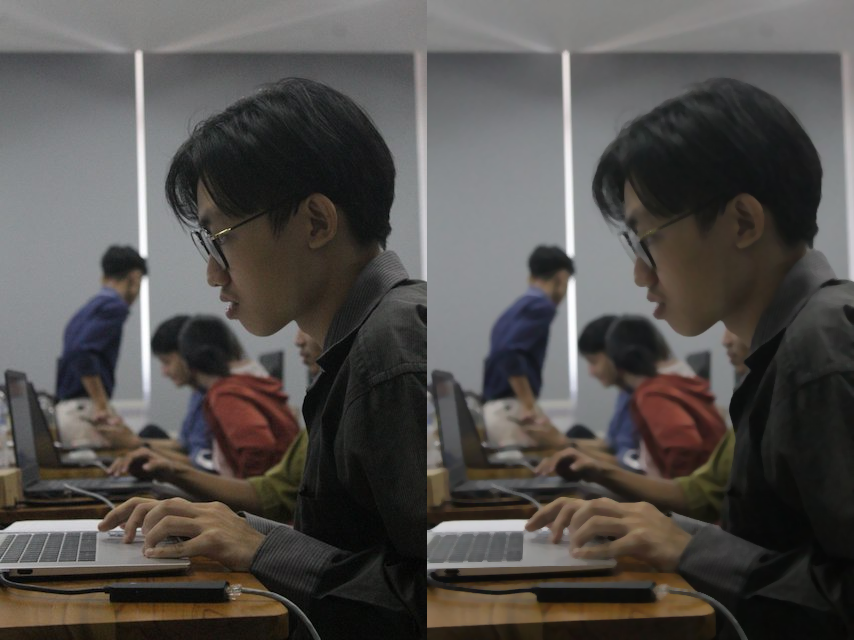

In [ ]:
dst3 = cv2.medianBlur(src, 5)

print("Median Filter")
cv2_imshow(np.hstack((src, dst3)))

### Bilateral Filter

Bilateral Filter


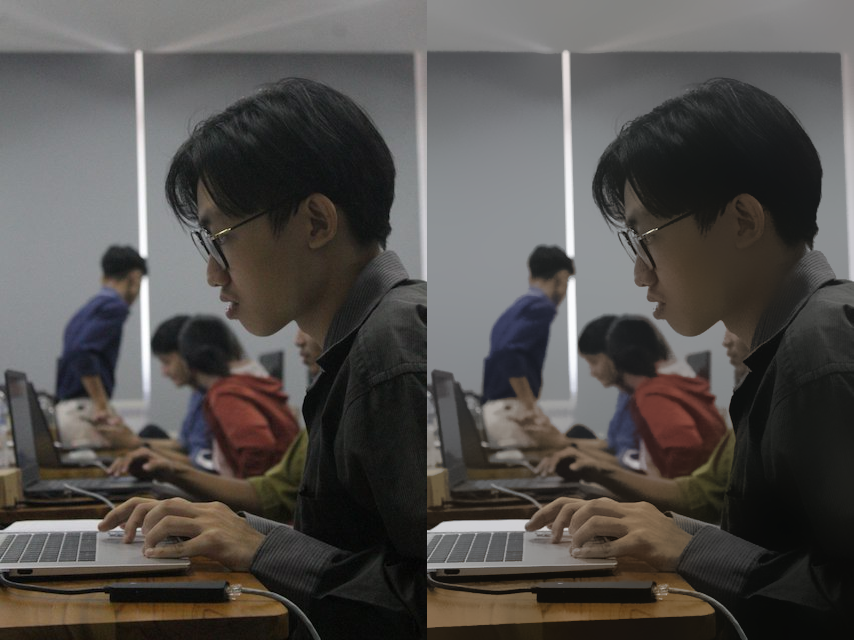

In [ ]:
dst4 = cv2.bilateralFilter(src, 50, 25, 25)

print("Bilateral Filter")
cv2_imshow(np.hstack((src, dst4)))

### Low Pass Filter

Low Pass


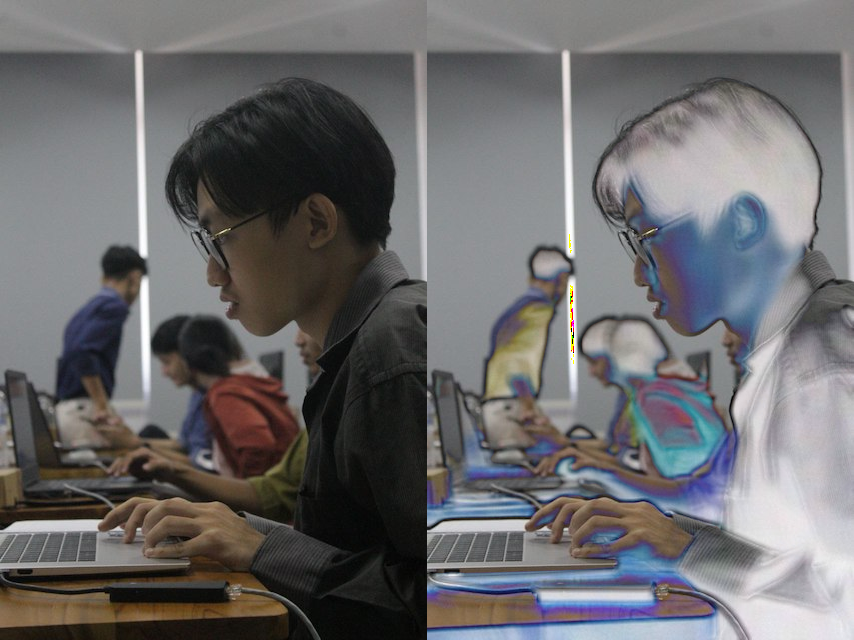

In [ ]:
Lp = cv2.filter2D(src,-1, kernel)
Lp = src - Lp

print("Low Pass")
cv2_imshow(np.hstack((src, Lp)))

### High Pass Filter

[[[2 2 2]]]
[[[129 129 129]]]
High Pass


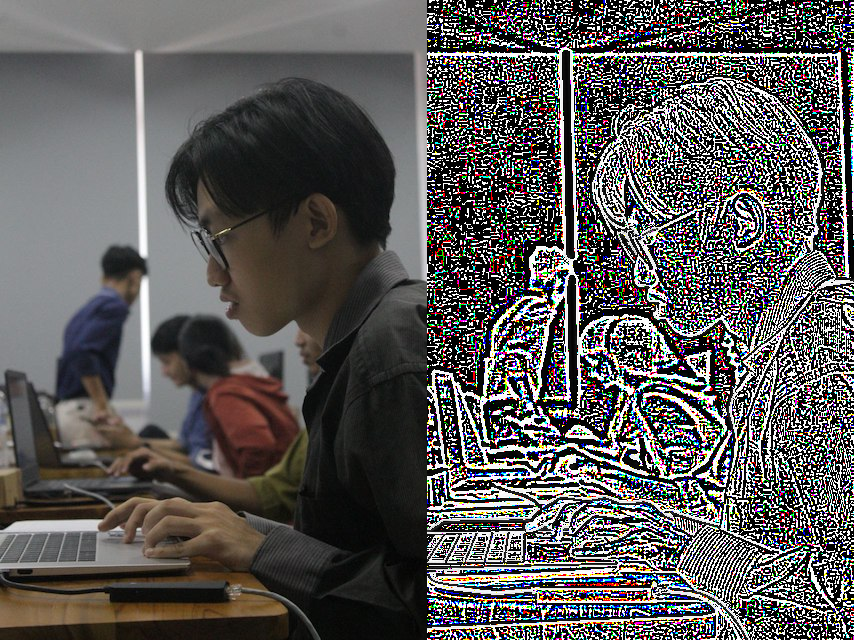

In [ ]:
Hp = src - dst
print(Hp[:1, :1])

filtered = Hp + 127 * np.ones(src.shape, np.uint8)
print(filtered[:1, :1])

print("High Pass")
cv2_imshow(np.hstack((src, Hp)))